# 1. Paywall price test: analysis against a known truth

A freemium subscription app tests a 20% lower price (9.99 to 7.99 per month) on free users who hit the paywall. 200,000 users are split 50/50 at random over 28 days. The primary metric is revenue per exposed user in the 30 days after enrollment, and the guardrails are 60-day revenue and the share of users still paying in month 2.

Why a simulation: with real data you never find out the true effect, so you can't tell if a method is right or just plausible. Here every user has both potential outcomes and I can grade each estimator. To keep myself honest, the `true_*` columns stay hidden until section 5.

Sections: 1 power, 2 validity checks, 3 main analysis, 4 CUPED, 5 comparison with the truth (Monte Carlo), 6 guardrails and time horizon, 7 effects by tier, 8 decision.

> Everything here is simulated. The parameters are my own assumptions (listed in the README), not data from a real company.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from IPython.display import display

from src.simulator import simulate, SimConfig
from src import analysis as an, power

from src.plotting import use_style, SURFACE, INK, INK2, MUTED, GRID, AXIS, BLUE, ORANGE
use_style()
pd.options.display.float_format = "{:,.4f}".format

df = simulate(SimConfig())                                   # 200k users, seed 42
observed = df.drop(columns=[c for c in df if c.startswith("true_")])   # what an analyst would really have
observed.head()

,user_id,enroll_day,treatment,tier,platform,sessions_pre,tenure_days,revenue_pre_30d,converted,retained_m2,revenue_30d,revenue_60d
0,23,0,1,T3,ios,17,193,0.0000,0,0,0.0000,0.0000
1,39,0,1,T2,android,24,1,0.0000,0,0,0.0000,0.0000
2,46,0,0,T2,ios,17,11,0.0000,0,0,0.0000,0.0000
3,76,0,0,T1,android,4,43,0.0000,0,0,0.0000,0.0000
4,82,0,1,T3,android,9,100,0.0000,0,0,0.0000,0.0000


## 1. What can this experiment detect?

I do the power calculation before looking at any result. It needs the standard deviation of the metric, the sample size and the correlation with a pre-experiment covariate (normally estimated on historical data, here on the control arm).

For a difference in means: $n_{\text{per arm}} = \dfrac{2\,(z_{1-\alpha/2}+z_{\text{power}})^2\,\sigma^2}{\delta^2}$, or equivalently $\text{MDE}=(z_{1-\alpha/2}+z_{\text{power}})\sqrt{2\sigma^2/n}$.

In [2]:
ctrl = observed[observed.treatment == 0]
sigma, arpu = ctrl.revenue_30d.std(), ctrl.revenue_30d.mean()
rho2 = np.corrcoef(ctrl.revenue_pre_30d, ctrl.revenue_30d)[0, 1] ** 2
n_arm = len(observed) // 2

print(f"Control conversion          : {ctrl.converted.mean():.2%}")
print(f"Control revenue / user (30d): {arpu:.3f}   sd = {sigma:.2f}   (sd/mean = {sigma/arpu:.1f}: very heavy tailed)")
print(f"Pre/post revenue corr^2     : {rho2:.2f}  -> CUPED can remove about {rho2:.0%} of the variance")
mde, mde_c = power.mde_mean(sigma, n_arm), power.mde_mean(sigma, n_arm, variance_reduction=rho2)
print(f"\nWith {n_arm:,} users/arm (alpha=5%, power=80%):")
print(f"  MDE, plain difference in means : {mde:.3f}  ({mde/arpu:.1%} of ARPU)")
print(f"  MDE, with CUPED               : {mde_c:.3f}  ({mde_c/arpu:.1%} of ARPU)")

Control conversion          : 4.82%
Control revenue / user (30d): 0.907   sd = 5.27   (sd/mean = 5.8: very heavy tailed)
Pre/post revenue corr^2     : 0.22  -> CUPED can remove about 22% of the variance

With 100,000 users/arm (alpha=5%, power=80%):
  MDE, plain difference in means : 0.066  (7.3% of ARPU)
  MDE, with CUPED               : 0.058  (6.4% of ARPU)


So with this sample only revenue changes of about 6-7% of ARPU are detectable (a bit less with CUPED). Anything smaller won't show up whatever the p-value says, and it's better to know that before the test starts.

## 2. Validity checks

Before reading any result I check two things:

1. Sample ratio mismatch (SRM): is the 50/50 split really 50/50? Chi-square test on the counts. The usual convention is to distrust the whole experiment if p < 0.001.
2. Covariate balance: randomization should balance the pre-experiment variables. I use standardized mean differences (|SMD| < 0.1 is the usual bar) instead of p-values, because with 200k users a p-value flags even trivial differences.

In [3]:
t, y, x = observed.treatment.to_numpy(), observed.revenue_30d.to_numpy(), observed.revenue_pre_30d.to_numpy()
print(f"Treatment {t.sum():,} vs control {(1-t).sum():,}  ->  SRM p-value = {an.srm_check(t.sum(), (1-t).sum()):.3f}")
print("\nSRM inside each tier (a bug can hide in one segment):")
for k, g in observed.groupby("tier"):
    print(f"  {k}: {g.treatment.sum():,} vs {(1-g.treatment).sum():,}  p = {an.srm_check(g.treatment.sum(), (1-g.treatment).sum()):.3f}")

bal = {c: an.standardized_mean_diff(observed[c].to_numpy().astype(float), t)
       for c in ["sessions_pre", "tenure_days", "revenue_pre_30d"]}
bal["share iOS"] = an.standardized_mean_diff((observed.platform == "ios").to_numpy().astype(float), t)
for k in ["T1", "T2", "T3"]:
    bal[f"share {k}"] = an.standardized_mean_diff((observed.tier == k).to_numpy().astype(float), t)
display(pd.Series(bal, name="SMD").to_frame().T)

Treatment 100,061 vs control 99,939  ->  SRM p-value = 0.785

SRM inside each tier (a bug can hide in one segment):
  T1: 35,012 vs 34,978  p = 0.898
  T2: 40,094 vs 39,979  p = 0.684
  T3: 24,955 vs 24,982  p = 0.904


,sessions_pre,tenure_days,revenue_pre_30d,share iOS,share T1,share T2,share T3
SMD,0.0020,-0.0000,0.0029,0.0091,-0.0002,0.0014,-0.0013


Both checks pass, so the data can be analysed. (In notebook 02 I break the assignment on purpose to see what an SRM looks like.)

## 3. Main analysis

Conversion is a simple 0/1 rate. Revenue per user is zero for most people and has a long right tail, so next to the normal-approximation interval I also compute a bootstrap one.

In [4]:
rows = []
for metric in ["converted", "revenue_30d"]:
    e = an.diff_in_means(observed[metric].to_numpy().astype(float), t)
    rows.append({"metric": metric, "control": observed.loc[t == 0, metric].mean(),
                 "treatment": observed.loc[t == 1, metric].mean(), "diff": e.estimate,
                 "ci_low": e.ci_low, "ci_high": e.ci_high, "p_value": e.p_value})
res = pd.DataFrame(rows).set_index("metric")
display(res)

b_lo, b_hi = an.bootstrap_diff(y, t, n_boot=1000)
print(f"Bootstrap 95% CI for revenue_30d diff: [{b_lo:+.4f}, {b_hi:+.4f}]   (normal approx: [{res.loc['revenue_30d','ci_low']:+.4f}, {res.loc['revenue_30d','ci_high']:+.4f}])")

,control,treatment,diff,ci_low,ci_high,p_value
metric,,,,,,
converted,0.0482,0.0581,0.0099,0.0079,0.0119,0.0000
revenue_30d,0.9074,0.8953,-0.0121,-0.0562,0.0320,0.5901


Bootstrap 95% CI for revenue_30d diff: [-0.0547, +0.0327]   (normal approx: [-0.0562, +0.0320])


Conversion goes up by about 1 percentage point with a tiny p-value, so the discount clearly brings in more payers. Revenue per user, on the other hand, can't be told apart from zero. Looking only at conversion I would have shipped the discount, but the lower price eats the revenue from the extra payers. The primary metric has to be the one the business cares about (revenue), even if it's the harder one to move.

## 4. CUPED

CUPED (Controlled-experiment Using Pre-Experiment Data) removes the part of the outcome that a covariate measured before the experiment already explains:

$$Y^{\text{adj}}_i = Y_i - \theta\,(X_i - \bar X),\qquad \theta=\frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)}$$

X is measured before randomization, so the treatment can't affect it and the estimate stays unbiased, while the variance shrinks by a factor $1-\rho^2$. Here X is the user's in-app spend in the 30 days before enrollment.

In [5]:
e_naive = an.diff_in_means(y, t)
e_cuped, vr = an.cuped_effect(y, x, t)
_, theta = an.cuped_adjust(y, x)

print(f"theta = {theta:.3f}   variance reduction = {vr:.1%}   (corr^2 on full sample = {np.corrcoef(x, y)[0,1]**2:.1%})")
print(f"Naive : {e_naive}")
print(f"CUPED : {e_cuped}")
print(f"\nCI width shrinks by {1 - (e_cuped.ci_high-e_cuped.ci_low)/(e_naive.ci_high-e_naive.ci_low):.1%}"
      f"  -> equivalent to {1/(1-vr):.2f}x more users, for free.")

theta = 0.528   variance reduction = 19.4%   (corr^2 on full sample = 19.4%)
Naive : -0.0121  95% CI [-0.0562, +0.0320]  se=0.0225  p=0.590
CUPED : -0.0186  95% CI [-0.0581, +0.0210]  se=0.0202  p=0.358

CI width shrinks by 10.2%  -> equivalent to 1.24x more users, for free.


The interval gets about 10% narrower, roughly the same as having 1.24x more users, but the conclusion doesn't change: still no detectable effect overall. The gain is modest because last month's spend explains only ~19% of the variance (most users never buy anything in-app). A regression on more pre-period features (CUPAC) could do better.

## 5. Comparing with the truth

Time to unblind. Since I know both potential outcomes for every user, I can compute the true effect and also re-run the experiment 2,000 times on random 40,000-user subsamples, with a new randomization each time. That gives the actual bias, coverage, power and false positive rate of each method.

In [6]:
true_ate = df.true_ite_revenue_30d.mean()
print(f"TRUE average effect on 30d revenue per user: {true_ate:+.4f}   (naive est {e_naive.estimate:+.4f}, CUPED est {e_cuped.estimate:+.4f})")
print(f"TRUE effect on conversion                  : {df.true_ite_converted.mean():+.4f}")

mc = an.monte_carlo(df, "revenue_30d", "revenue_pre_30d", n_users=40_000, n_reps=2000, seed=1)
aa = an.monte_carlo(df, "revenue_30d", "revenue_pre_30d", n_users=40_000, n_reps=2000, true_effect_override=0.0, seed=2)

def summarize(r):
    return pd.DataFrame({
        "mean estimate": [r.naive_est.mean(), r.cuped_est.mean()],
        "empirical sd": [r.naive_est.std(), r.cuped_est.std()],
        "mean reported se": [r.naive_se.mean(), r.cuped_se.mean()],
        "95% CI coverage": [r.naive_covers.mean(), r.cuped_covers.mean()],
        "share p<0.05": [(r.naive_p < .05).mean(), (r.cuped_p < .05).mean()],
    }, index=["Naive", "CUPED"])

print(f"\n--- 2,000 replications, real effect = {mc.attrs['target']:+.4f} ---"); display(summarize(mc))
print("--- 2,000 A/A replications (effect forced to 0): share p<0.05 is the false-positive rate ---"); display(summarize(aa))
print(f"Std. error ratio CUPED/naive = {mc.cuped_est.std()/mc.naive_est.std():.3f}   vs sqrt(1 - corr^2) = {np.sqrt(1-rho2):.3f}")

TRUE average effect on 30d revenue per user: -0.0145   (naive est -0.0121, CUPED est -0.0186)
TRUE effect on conversion                  : +0.0102



--- 2,000 replications, real effect = -0.0145 ---


,mean estimate,empirical sd,mean reported se,95% CI coverage,share p<0.05
Naive,-0.0147,0.0505,0.0498,0.9495,0.0635
CUPED,-0.0151,0.0451,0.0446,0.9475,0.0635


--- 2,000 A/A replications (effect forced to 0): share p<0.05 is the false-positive rate ---


,mean estimate,empirical sd,mean reported se,95% CI coverage,share p<0.05
Naive,0.0014,0.0499,0.0507,0.9460,0.0540
CUPED,0.0006,0.0443,0.0455,0.9485,0.0515


Std. error ratio CUPED/naive = 0.893   vs sqrt(1 - corr^2) = 0.883


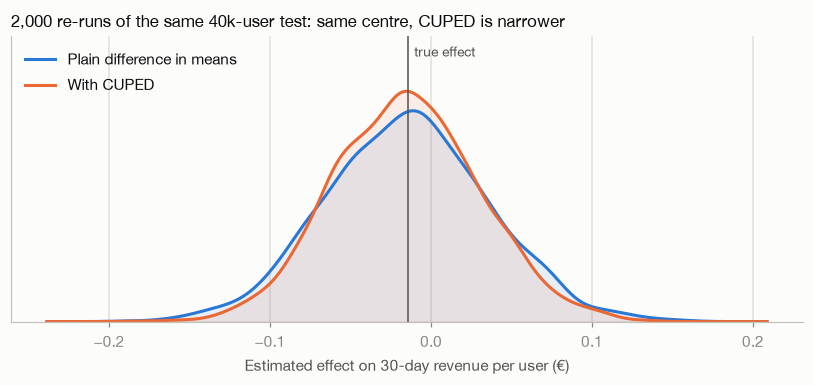

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
grid = np.linspace(mc.naive_est.min() - 0.05, mc.naive_est.max() + 0.05, 400)
for col, color, label in [("naive_est", BLUE, "Plain difference in means"), ("cuped_est", ORANGE, "With CUPED")]:
    dens = gaussian_kde(mc[col])(grid)
    ax.plot(grid, dens, color=color, lw=2, label=label)
    ax.fill_between(grid, dens, color=color, alpha=0.10)
ymax = ax.get_ylim()[1]; ax.set_ylim(0, ymax * 1.18)
ax.axvline(mc.attrs["target"], color=INK2, lw=1)
ax.text(mc.attrs["target"] + 0.004, ymax * 1.15, "true effect", color=INK2, fontsize=9, va="top")
ax.set_xlabel("Estimated effect on 30-day revenue per user (€)"); ax.set_yticks([])
ax.set_title("2,000 re-runs of the same 40k-user test: same centre, CUPED is narrower", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper left"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("../reports/figures/01_montecarlo_cuped.png", dpi=160); plt.show()

What the re-runs show:
- Both estimators are unbiased (the mean estimate is close to the true effect) and their 95% intervals contain the truth about 95% of the time.
- In A/A tests the false positive rate is about 5%, as it should be.
- The spread of the CUPED estimates is smaller by $\sqrt{1-\rho^2}$, matching the theory.
- When the effect is real, though, the share of runs with p < 0.05 is barely above 5% for both. The average effect is tiny compared to the noise, so a test this size almost never finds it. The next chart shows that more data wouldn't really fix this.

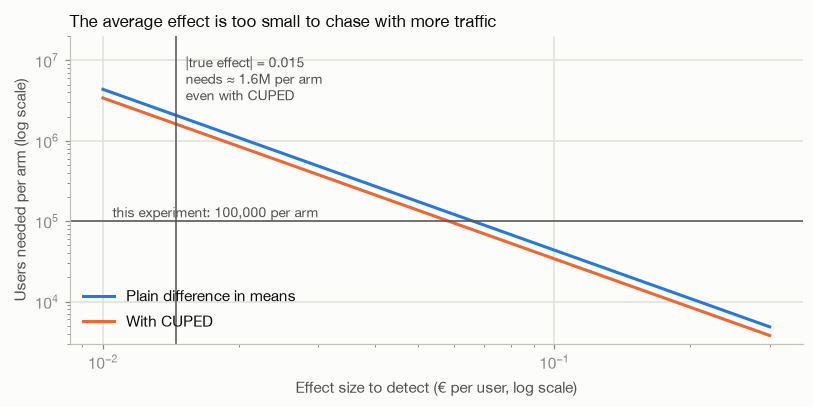

In [8]:
mdes = np.logspace(np.log10(0.01), np.log10(0.3), 120)
n_plain = [power.n_per_arm_mean(sigma, d) for d in mdes]
n_cup = [power.n_per_arm_mean(sigma, d, variance_reduction=rho2) for d in mdes]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(mdes, n_plain, color=BLUE, lw=2, label="Plain difference in means")
ax.plot(mdes, n_cup, color=ORANGE, lw=2, label="With CUPED")
ax.axhline(n_arm, color=INK2, lw=1); ax.text(0.0105, n_arm * 1.12, f"this experiment: {n_arm:,} per arm", color=INK2, fontsize=9)
ax.axvline(abs(true_ate), color=INK2, lw=1)
need = power.n_per_arm_mean(sigma, abs(true_ate), variance_reduction=rho2)
ax.text(abs(true_ate) * 1.05, 2e7 * 0.6, f"|true effect| = {abs(true_ate):.3f}\nneeds ≈ {need/1e6:.1f}M per arm\neven with CUPED", color=INK2, fontsize=9, va="top")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(3e3, 2e7)
ax.set_xlabel("Effect size to detect (€ per user, log scale)"); ax.set_ylabel("Users needed per arm (log scale)")
ax.set_title("The average effect is too small to chase with more traffic", loc="left", fontsize=11, color=INK)
ax.legend(loc="lower left"); fig.tight_layout(); fig.savefig("../reports/figures/01_sample_size_vs_effect.png", dpi=160); plt.show()

To detect the true average effect I'd need millions of users per arm. When the average is close to zero because positive and negative effects cancel out, a bigger test won't help much. The useful question is for whom the discount works, which is section 7.

## 6. Guardrails and time horizon

A discount can look neutral after 30 days and worse after 60 if the extra payers churn faster, and in this simulation they do (users who convert only because of the discount are less likely to renew in month 2).

For retention I use retained payers per exposed user (paying and still paying in month 2) instead of retention among payers. Retention among payers conditions on something the treatment changes, namely who becomes a payer, so the payer groups of the two arms aren't comparable.

In [9]:
rows = []
for metric, truth in [("revenue_30d", "true_ite_revenue_30d"), ("revenue_60d", "true_ite_revenue_60d")]:
    yy = df[metric].to_numpy(); xx = df.revenue_pre_30d.to_numpy(); tt = df.treatment.to_numpy()
    e, _ = an.cuped_effect(yy, xx, tt)
    rows.append({"metric": metric, "CUPED estimate": e.estimate, "ci_low": e.ci_low, "ci_high": e.ci_high,
                 "p_value": e.p_value, "TRUE effect": df[truth].mean()})
e = an.diff_in_means(df.retained_m2.to_numpy().astype(float), df.treatment.to_numpy())
rows.append({"metric": "retained_m2 (per exposed user)", "CUPED estimate": e.estimate, "ci_low": e.ci_low,
             "ci_high": e.ci_high, "p_value": e.p_value, "TRUE effect": np.nan})
display(pd.DataFrame(rows).set_index("metric"))

,CUPED estimate,ci_low,ci_high,p_value,TRUE effect
metric,,,,,
revenue_30d,-0.0186,-0.0581,0.0210,0.3576,-0.0145
revenue_60d,-0.0501,-0.0966,-0.0037,0.0342,-0.0384
retained_m2 (per exposed user),0.0037,0.0021,0.0052,0.0000,NaN


At 60 days the revenue effect is more negative than at 30, and this time the interval excludes zero (p ~ 0.03; it's a secondary metric, so I wouldn't lean too hard on a p-value that close to 0.05). Looking only at the first month would make the discount look better than it is.

Retained payers per exposed user actually go up, because the discount does create more payers. Revenue still drops since every payer pays 20% less and the ones won by the discount churn more. (There's no ground-truth column for month-2 retained payers, so that row has no "true" value.)

## 7. Effects by tier

Price sensitivity differs by country tier (T1 = high purchasing power, T3 = low). Tier is known before the experiment and was planned as a segment from the start, so testing its 3 levels is a legitimate family of hypotheses, and I correct the 3 p-values with Holm. Slicing by dozens of variables until something comes out significant would be p-hacking; notebook 03 looks for segments with a proper model instead. Each tier is CUPED-adjusted with the same global $\theta$.

In [10]:
df["revenue_30d_cuped"], _ = an.cuped_adjust(df.revenue_30d.to_numpy(), df.revenue_pre_30d.to_numpy())
sg_plain = an.subgroup_effects(df, "tier", "revenue_30d", truth="true_ite_revenue_30d")
sg = an.subgroup_effects(df, "tier", "revenue_30d_cuped", truth="true_ite_revenue_30d")
cmp_ = sg_plain[["tier", "n", "estimate", "ci_low", "ci_high"]].merge(
    sg[["tier", "estimate", "ci_low", "ci_high", "p_value", "p_holm", "true_effect"]], on="tier", suffixes=(" (naive)", " (CUPED)"))
display(cmp_.set_index("tier"))

,n,estimate (naive),ci_low (naive),ci_high (naive),estimate (CUPED),ci_low (CUPED),ci_high (CUPED),p_value,p_holm,true_effect
tier,,,,,,,,,,
T1,69990,-0.0746,-0.1498,0.0006,-0.1051,-0.1726,-0.0375,0.0023,0.0069,-0.0846
T2,80073,0.0009,-0.0668,0.0685,-0.0007,-0.0617,0.0603,0.9827,0.9827,-0.0117
T3,49937,0.0545,-0.0363,0.1453,0.0739,-0.0071,0.1548,0.0736,0.1472,0.0791


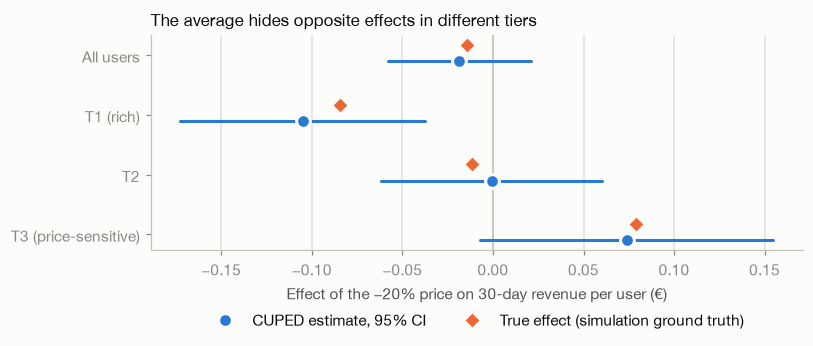

In [11]:
overall, _ = an.cuped_effect(df.revenue_30d.to_numpy(), df.revenue_pre_30d.to_numpy(), df.treatment.to_numpy())
labels = ["All users", "T1 (rich)", "T2", "T3 (price-sensitive)"]
est = [overall.estimate, *sg.estimate]; lo = [overall.ci_low, *sg.ci_low]; hi = [overall.ci_high, *sg.ci_high]
truth = [true_ate, *sg.true_effect]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ypos = np.arange(len(labels))[::-1]
ax.axvline(0, color=AXIS, lw=1)
for yp, l, h in zip(ypos, lo, hi):
    ax.plot([l, h], [yp - 0.1, yp - 0.1], color=BLUE, lw=2, solid_capstyle="round")
ax.plot(est, ypos - 0.1, "o", color=BLUE, ms=9, mec=SURFACE, mew=2, label="CUPED estimate, 95% CI")
ax.plot(truth, ypos + 0.17, "D", color=ORANGE, ms=8, mec=SURFACE, mew=2, label="True effect (simulation ground truth)")
ax.set_yticks(ypos, labels); ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect of the −20% price on 30-day revenue per user (€)")
ax.set_title("The average hides opposite effects in different tiers", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
fig.tight_layout(); fig.savefig("../reports/figures/01_effect_by_tier.png", dpi=160, bbox_inches="tight"); plt.show()

The overall "no effect" is an average of effects going in opposite directions, and in every tier the interval contains the true value.
- T1: the discount loses money, and this survives the multiple-testing correction (Holm p < 0.01).
- T2: about zero.
- T3: the point estimate is positive but the interval still touches zero (Holm p ~ 0.15).

Each tier has only 25-40% of the users, so confirming an effect inside one tier on such a noisy metric is much harder than for the overall effect.

## 8. From estimates to a decision

I convert the effects into money per million eligible users and compare a few policies. Each policy is a rule an analyst could actually apply with this data, and I then score it with the true effects (which you wouldn't have in real life). For the targeted policy I try two selection rules: a strict one (only tiers with a Holm-significant gain) and an exploratory one (any tier with a positive estimate).

In [12]:
share = df.tier.value_counts(normalize=True)
N = 1_000_000
def value(tiers, col):                                    # true € impact of shipping the variant in `tiers`
    return N * sum(share[k] * df.loc[df.tier == k, col].mean() for k in tiers)

strict = sg.loc[(sg.estimate > 0) & (sg.p_holm < 0.05), "tier"].tolist()
exploratory = sg.loc[sg.estimate > 0, "tier"].tolist()
policies = [("Keep control price", []),
            ("Ship variant to everyone", ["T1", "T2", "T3"]),
            (f"Strict targeting {strict} (Holm-significant gain)", strict),
            (f"Exploratory targeting {exploratory} (point estimate > 0)", exploratory)]
table = pd.DataFrame([{"policy": n, "TRUE € per 1M users, 30d": value(tr, "true_ite_revenue_30d"),
                       "TRUE € per 1M users, 60d": value(tr, "true_ite_revenue_60d")} for n, tr in policies]).set_index("policy")
display(table.map(lambda v: f"{v:,.0f}"))

,"TRUE € per 1M users, 30d","TRUE € per 1M users, 60d"
policy,,
Keep control price,0,0
Ship variant to everyone,"-14,522","-38,357"
Strict targeting [] (Holm-significant gain),0,0
Exploratory targeting ['T3'] (point estimate > 0),"19,755","25,166"


Shipping to everyone is the only clearly bad option. The strict rule picks nothing because T3 isn't confirmed with this sample, so it ends up equal to keeping the control price: safe, but it leaves the T3 gain on the table. The exploratory rule picks T3 and in this simulation it would make money, but an analyst couldn't know that from the data alone. Picking the best-looking segment and measuring it on the same data overstates the gain (winner's curse).

What I'd actually recommend is a confirmatory test in T3 only. How big would it need to be?

In [13]:
g3 = df[df.tier == "T3"]
c3 = g3[g3.treatment == 0]
sigma3 = c3.revenue_30d.std()
rho2_3 = np.corrcoef(c3.revenue_pre_30d, c3.revenue_30d)[0, 1] ** 2
est3 = sg.loc[sg.tier == "T3", "estimate"].iloc[0]
daily_t3 = len(g3) / 28                                     # T3 users enrolled per day in this experiment

print(f"T3 point estimate: {est3:+.3f} €/user. Plan for HALF of it ({est3/2:+.3f}) to be conservative about the winner's curse.")
for label, vr in [("plain", 0.0), ("with CUPED", rho2_3)]:
    n = power.n_per_arm_mean(sigma3, est3 / 2, variance_reduction=vr)
    print(f"  {label:11s}: {n:>9,} users per arm  ->  {power.duration_days(2*n, daily_t3):>4} days at {daily_t3:,.0f} T3 users/day")

T3 point estimate: +0.074 €/user. Plan for HALF of it (+0.037) to be conservative about the winner's curse.
  plain      :   388,018 users per arm  ->   436 days at 1,783 T3 users/day
  with CUPED :   258,881 users per arm  ->   291 days at 1,783 T3 users/day


A confirmation on revenue in T3 alone would take many months at the current traffic, which isn't realistic. There are three ways to shorten it, and they're what the next notebooks do: use a less noisy outcome like conversion together with the known price (notebook 03 does this and the noise drops a lot), use sequential testing so a clear result can stop early (notebook 02), and estimate the segment effect with a model that borrows strength across users (notebook 03).

## Summary

1. The headline result ("no significant change in revenue") was correct and almost useless on its own: the average mixes a loss in T1 with a probable gain in T3.
2. Conversion going up was a misleading success metric. Revenue is the right primary metric, and the 60-day view made the discount look worse.
3. CUPED was worth about 1.24x the data here, and the Monte Carlo shows that the intervals behave as they should.
4. Confirming an effect inside a segment takes far more data than the overall test, so segments have to be planned (decided beforehand, corrected for multiplicity, confirmed in a follow-up) instead of found after the fact.

Next: notebook 02 covers peeking, sequential testing, SRM bugs and novelty effects, 03 uplift modelling, 04 the real Hillstrom e-mail experiment and 05 the same analysis in SQL.